# Simulated person: linear observer in a 2IFC RC task

Implements the model in [model/01-simulated-person-on-paper.md](../model/01-simulated-person-on-paper.md), one function at a time.

| Equation | Function | Status |
|---|---|---|
| θ random, length 1 | `make_template(d)` | ✅ this notebook |
| n ~ N(0, I) | `make_noise(n_trials, d)` | ✅ this notebook |
| choose base + n if θᵀn + ε > 0 | `observer_choose(theta, noise, sigma)` | to do |
| CI = Σ s·n | `classification_image(noise, s)` | to do |
| cos(CI, θ) | `cosine(a, b)` | to do |

In [19]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 2026
rng = np.random.default_rng(SEED)

## 1. `make_template(d)` → θ

The hidden template θ is a **random unit vector** in d dimensions:

1. draw g ~ N(0, I_d);
2. set θ = g / ‖g‖.

Because N(0, I) is spherically symmetric, θ is **uniform over the unit sphere**: no direction is favoured.

In [20]:
def make_template(d, rng=None):
    """Return a random unit vector θ of shape (d,), uniform over the sphere in R^d.

    Parameters
    ----------
    d : int
        Number of dimensions of the stimulus space (d >= 1).
    rng : np.random.Generator, optional
        Random generator, for reproducible runs. A fresh one is created if None.
    """
    if int(d) != d or d < 1:
        raise ValueError(f"d must be a positive integer, got {d!r}")
    rng = np.random.default_rng() if rng is None else rng
    g = rng.standard_normal(int(d))
    return g / np.linalg.norm(g)

## 2. Checks

In [21]:
d = 10
theta = make_template(d, rng)
print("theta =", np.round(theta, 3))
print("shape =", theta.shape, "| norm =", np.linalg.norm(theta))

# Unit length
assert theta.shape == (d,)
assert np.isclose(np.linalg.norm(theta), 1.0)

# Reproducible: same seed -> same template
a = make_template(d, np.random.default_rng(1))
b = make_template(d, np.random.default_rng(1))
assert np.array_equal(a, b)

# Bad input is rejected
for bad in (0, -3, 2.5):
    try:
        make_template(bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"make_template({bad}) should fail")
print("All checks passed.")

theta = [-0.299  0.091 -0.715  0.526  0.241 -0.11  -0.118  0.115 -0.101 -0.085]
shape = (10,) | norm = 1.0
All checks passed.


### Is θ really uniform on the sphere?

Draw many templates. If θ is uniform:

- every coordinate has mean ≈ 0 and variance ≈ 1/d;
- the cosine between two independent templates (a pure "random guess" in §4 of the model) has **mean ≈ 0**, mean |cos| ≈ 0.26 and **RMS ≈ 1/√d ≈ 0.32** for d = 10.

max |mean of a coordinate| : 0.0035
variance per coordinate    : [0.1015 0.1    0.1007 0.1005 0.0988 0.1001 0.0991 0.0985 0.1011 0.0996] (expected 0.1000)

random-guess cosine: mean = 0.000, mean |cos| = 0.258, RMS = 0.314 (1/sqrt(d) = 0.316)


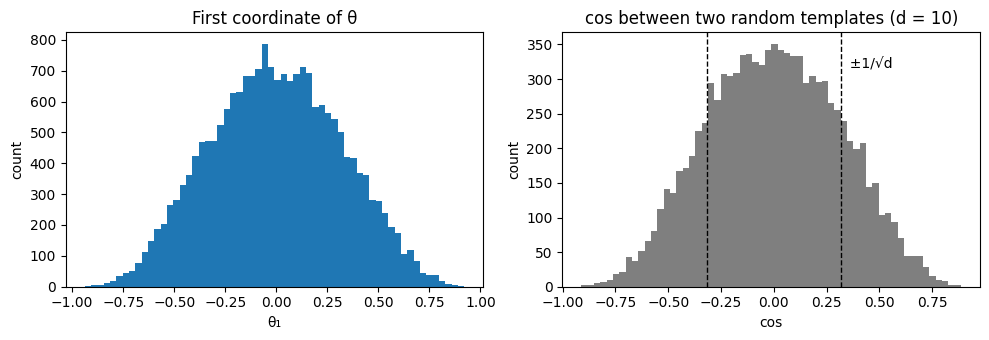

In [22]:
n_templates = 20_000
thetas = np.stack([make_template(d, rng) for _ in range(n_templates)])

print("max |mean of a coordinate| :", np.abs(thetas.mean(axis=0)).max().round(4))
print("variance per coordinate    :", thetas.var(axis=0).round(4), f"(expected {1/d:.4f})")

# Cosine between pairs of independent templates (all unit length, so cos = dot product)
cos_random = np.sum(thetas[0::2] * thetas[1::2], axis=1)
print(f"\nrandom-guess cosine: mean = {cos_random.mean():.3f}, "
      f"mean |cos| = {np.abs(cos_random).mean():.3f}, "
      f"RMS = {np.sqrt(np.mean(cos_random**2)):.3f} (1/sqrt(d) = {1/np.sqrt(d):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(thetas[:, 0], bins=60, color="tab:blue")
axes[0].set(title="First coordinate of θ", xlabel="θ₁", ylabel="count")
axes[1].hist(cos_random, bins=60, color="tab:gray")
for x in (-1/np.sqrt(d), 1/np.sqrt(d)):
    axes[1].axvline(x, ls="--", color="k", lw=1)
axes[1].set(title=f"cos between two random templates (d = {d})", xlabel="cos", ylabel="count")
axes[1].text(1/np.sqrt(d), axes[1].get_ylim()[1]*0.9, "  ±1/√d", va="top")
plt.tight_layout()
plt.show()

## 3. `make_noise(n_trials, d)` → noise vectors

One noise pattern per trial, each drawn independently: **n_t ~ N(0, I_d)**.

Returned as an array of shape **(n_trials, d)**: row t is n_t. On trial t the two images are *base + n_t* and *base − n_t*.

Because ‖θ‖ = 1 and N(0, I) is spherically symmetric, the projection **θᵀn_t ~ N(0, 1)** whatever θ is. That is why σ in the model is directly the internal-to-stimulus noise ratio.

In [23]:
def make_noise(n_trials, d, rng=None):
    """Return noise patterns of shape (n_trials, d); row t is n_t ~ N(0, I_d), independent across trials.

    Parameters
    ----------
    n_trials : int
        Number of trials N (>= 1).
    d : int
        Number of dimensions of the stimulus space (>= 1).
    rng : np.random.Generator, optional
        Random generator, for reproducible runs. A fresh one is created if None.
    """
    for name, value in (("n_trials", n_trials), ("d", d)):
        if int(value) != value or value < 1:
            raise ValueError(f"{name} must be a positive integer, got {value!r}")
    rng = np.random.default_rng() if rng is None else rng
    return rng.standard_normal((int(n_trials), int(d)))

### Checks

In [24]:
n_trials = 300
noise = make_noise(n_trials, d, rng)
print("shape =", noise.shape)
assert noise.shape == (n_trials, d)

# Reproducible: same seed -> same noise
assert np.array_equal(make_noise(5, d, np.random.default_rng(1)),
                      make_noise(5, d, np.random.default_rng(1)))

# Bad input is rejected
for bad in ((0, d), (n_trials, 0), (2.5, d), (n_trials, -1)):
    try:
        make_noise(*bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"make_noise{bad} should fail")

# Distribution: mean 0 and covariance I, over many trials
big = make_noise(200_000, d, rng)
cov = np.cov(big, rowvar=False)
print("max |mean|               :", np.abs(big.mean(axis=0)).max().round(4))
print("max |cov - I|            :", np.abs(cov - np.eye(d)).max().round(4))

# Projection on a unit template is N(0, 1).
# errstate: NumPy 2.0 + macOS system BLAS can emit false divide/overflow warnings from `@`;
# the assert below checks that the result itself is fine.
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    proj = big @ theta
assert np.isfinite(proj).all()
print(f"theta^T n: mean = {proj.mean():.3f}, SD = {proj.std():.3f} (expected 0 and 1)")
print("All checks passed.")

shape = (300, 10)
max |mean|               : 0.0041
max |cov - I|            : 0.0059
theta^T n: mean = -0.001, SD = 0.999 (expected 0 and 1)
All checks passed.


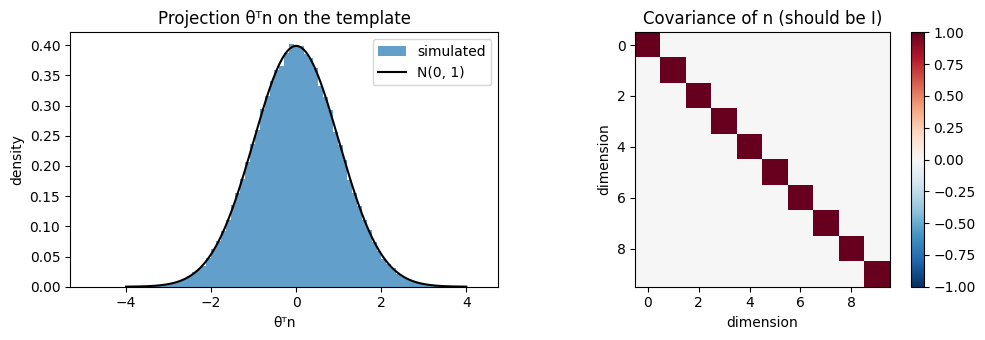

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

x = np.linspace(-4, 4, 200)
axes[0].hist(proj, bins=80, density=True, color="tab:blue", alpha=0.7, label="simulated")
axes[0].plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k", lw=1.5, label="N(0, 1)")
axes[0].set(title="Projection θᵀn on the template", xlabel="θᵀn", ylabel="density")
axes[0].legend()

im = axes[1].imshow(cov, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set(title="Covariance of n (should be I)", xlabel="dimension", ylabel="dimension")
fig.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()